# Identity-swap check from fish size: Shiv, `2024-10-23T15_18_28`

The same checks as in `Identity_swap_check_Shiv.ipynb` (methods described there), applied to this recording. All times are video time in **m:ss.s** (50 fps).

* **A, continuous**: 2 s rolling median of each label's area. Episode = the sizes of a pair fit better exchanged (`swap_ij > 0`) for ≥ 1 s.
* **B, encounters**: each label's median area 1–11 s before vs after every close approach. `enc_swap > 0` = the labels leave with each other's sizes.

**All potential swaps** = every A episode plus every encounter with `enc_swap ≥ 0`. Candidates less than 5 s apart are merged into one event.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, Video

os.chdir('/Volumes/Lenca_SSD/github/social_electric_fish')
import tracking_compare as tc
import identity_check as ic
%matplotlib inline
pd.set_option('display.precision', 2)

REC = '2024-10-23T15_18_28'
MP4 = 'data/elephantnose_2024-10-23_15_18_28_tracking_final.mp4'
OUT = os.path.join('figures', 'identity_check', REC)
os.makedirs(os.path.join(OUT, 'clips'), exist_ok=True)

recs = tc.find_recordings()
row = recs[(recs.tracker == 'Shiv') & (recs.recording == REC)].iloc[0]
R = ic.analyse(REC, row.path, 'figures/mask_metrics/elephantnose_2024-10-23_15_18_28/metrics.pkl')
fps, FISH, NAME = R['fps'], R['fish'], tc.FISH_NAME['Shiv']
COLOR = dict(zip(FISH, tc.mm.PALETTE))
ref, length, area, smooth, drift = R['ref'], R['length'], R['area'], R['smooth'], R['drift']
ts = lambda f: ic.mmss(f, fps)

order = ref.sort_values(ascending=False).index
pd.DataFrame({'fish': [NAME[l] for l in order], 'typical area (px)': ref[order].values,
              'typical length (px)': length[order].values,
              'size ratio to next smaller': (ref[order] / ref[order].shift(-1)).values,
              '% frames with usable area': 100 * area[order].notna().mean().values})

,fish,typical area (px),typical length (px),size ratio to next smaller,% frames with usable area
0,1 largest,4661.0,248.22,1.72,95.88
1,2 second,2707.0,200.30,1.18,98.37
2,3 third,2298.0,174.89,1.74,93.16
3,0 smallest,1317.0,128.56,NaN,89.03


## Size over time

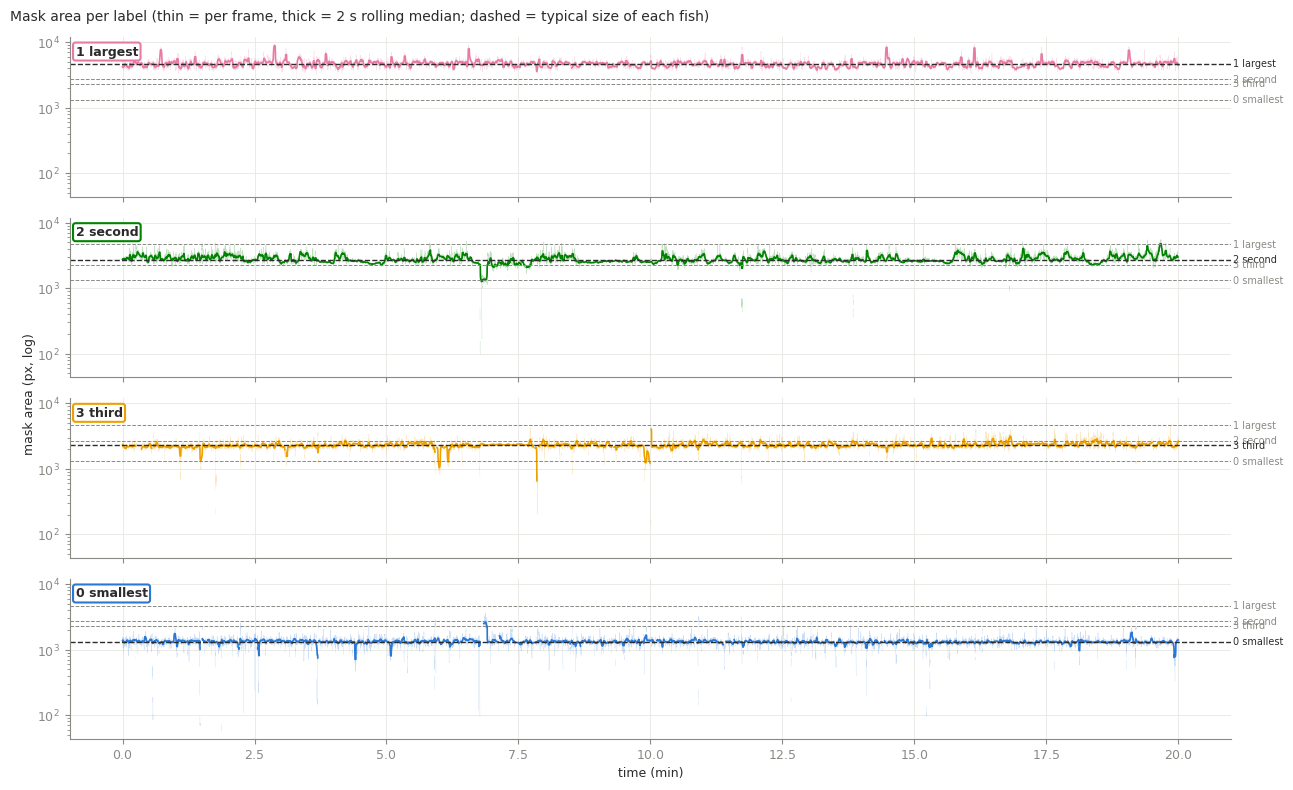

In [2]:
fig, axes = plt.subplots(len(FISH), 1, figsize=(13, 8), sharex=True, sharey=True)
t = area.index / fps / 60
for ax, lab in zip(axes, FISH):
    ax.plot(t, area[lab], color=COLOR[lab], lw=0.3, alpha=0.25, rasterized=True)
    ax.plot(t, smooth[lab], color=COLOR[lab], lw=1.2, rasterized=True)
    for other in FISH:
        ax.axhline(ref[other], color=tc.mm.INK if other == lab else tc.mm.MUTED,
                   lw=1 if other == lab else 0.7, ls='--')
        ax.text(1.002, ref[other], NAME[other], transform=ax.get_yaxis_transform(), fontsize=7,
                va='center', color=tc.mm.INK if other == lab else tc.mm.MUTED)
    tc.mm.fish_label(ax, lab, dict(fish_name=NAME, fish_color=COLOR))
    ax.set_yscale('log')
axes[-1].set_xlabel('time (min)')
fig.supylabel('mask area (px, log)', fontsize=9)
fig.suptitle('Mask area per label (thin = per frame, thick = 2 s rolling median; dashed = typical size of each fish)',
             x=0.01, ha='left', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'area_tracks.png'), dpi=150)

## All potential swaps

In [3]:
ep = R['episodes'].assign(source='A', score=lambda d: d.peak_score)
es = R['enc_swap']
enc_pos = es[es.enc_swap >= 0].assign(source='B', score=lambda d: d.enc_swap)
cand = pd.concat([ep[['source', 'pair', 'start', 'end', 'score']],
                  enc_pos[['source', 'pair', 'start', 'end', 'score']]]).sort_values('start', ignore_index=True)

events, cur = [], None
for c in cand.itertuples():
    if cur is not None and c.start <= cur['end'] + 5 * fps:
        cur['end'] = max(cur['end'], c.end)
        cur['found by'].append(f'{c.source} {c.pair} ({c.score:+.2f})')
        cur['max score'] = max(cur['max score'], c.score)
    else:
        cur = {'start': c.start, 'end': c.end, 'found by': [f'{c.source} {c.pair} ({c.score:+.2f})'], 'max score': c.score}
        events.append(cur)
events = pd.DataFrame(events)
events['found by'] = events['found by'].map(', '.join)
events.insert(0, 'from', events.start.map(ts))
events.insert(1, 'to', events.end.map(ts))
events.insert(2, 'duration (s)', (events.end - events.start + 1) / fps)
S = R['series']
for lab in FISH:
    s = S[lab]
    at_wall = (s.cx < 130) | (s.cy < 130) | (s.cx > 782) | (s.cy > 782)
    events[f'% at wall: {lab}'] = [100 * at_wall.iloc[a:b + 1].mean() for a, b in zip(events.start, events.end)]
events.to_csv(os.path.join(OUT, 'potential_swaps.csv'), index=False)
display(Markdown(f'**{len(cand)}** candidates (A: {len(ep)}, B: {len(enc_pos)}) merged into **{len(events)}** events.'))
events.drop(columns=['start', 'end'])

**35** candidates (A: 28, B: 7) merged into **20** events.

,from,to,duration (s),found by,max score,% at wall: 1,% at wall: 2,% at wall: 3,% at wall: 0
0,4:39.3,4:40.4,1.14,A 2-3 (+0.12),0.12,0.0,100.00,0.00,0.0
1,5:58.6,6:00.5,1.92,A 3-0 (+0.25),0.25,0.0,0.00,0.00,0.0
2,6:43.4,7:06.7,23.32,"B 3-0 (+0.00), A 2-3 (+0.11), A 2-0 (+1.36), A...",1.36,0.0,12.18,87.82,0.0
3,7:12.8,7:18.3,5.48,"A 2-3 (+0.04), A 2-3 (+0.07)",0.07,0.0,0.00,100.00,0.0
4,7:28.3,7:29.8,1.56,A 2-3 (+0.08),0.08,0.0,0.00,100.00,0.0
5,7:38.9,7:51.8,12.90,"A 2-3 (+0.04), A 2-3 (+0.33), B 2-3 (+0.00)",0.33,0.0,0.00,37.67,0.0
6,8:35.9,8:37.2,1.30,A 2-3 (+0.09),0.09,0.0,18.46,0.00,0.0
7,8:52.2,8:54.9,2.72,A 2-3 (+0.13),0.13,0.0,100.00,0.00,0.0
8,9:37.2,9:38.6,1.44,A 2-3 (+0.10),0.10,0.0,100.00,0.00,0.0
9,9:53.4,9:59.5,6.18,"A 3-0 (+0.46), A 3-0 (+0.09)",0.46,0.0,100.00,0.00,0.0


### Visual check of every event (by eye in the annotated video, 2026-10-29)
| event starts | what happens | swap? |
|---|---|---|
| 4:39.3 | label 2 at the top-left wall (looks smaller); stays on the corner fish | no: wall |
| 5:58.6 | label 3 partly under the large fish (pink), so its mask shrinks | no: occlusion |
| 6:43.4 | labels 2↔3 exchange at 6:46.26; 2↔0 swap back at 6:54.5 | **YES** |
| 7:12.8 | inside the confirmed swap period (label 2 on true fish 3) | **YES** (part of 6:46–7:44) |
| 7:28.3 | inside the confirmed swap period | **YES** (part of 6:46–7:44) |
| 7:38.9 | the 2↔3 swap resolves at 7:44.5 when the corner fish crosses the others | **YES** (end of swap) |
| 8:35.9 | green leaves the corner, crosses the others and returns to the corner with green | no |
| 8:52.2 | label 2 at the wall, sizes within posture noise | no: wall |
| 9:37.2 | label 2 at the wall | no: wall |
| 9:53.4 | label 3 crosses under the large fish (pink) and shrinks; label 0 normal | no: occlusion |
| 10:44.4 | label 2 along the top wall | no: wall |
| 11:04.2 | green swims out of the corner next to pink and back | no |
| 11:27.0 | label 2 at the wall | no: wall |
| 11:40.6 | label 2 stays at the wall; others in the middle | no: wall |
| 13:22.4 | label 2 at the wall | no: wall |
| 14:46.9 | label 2 at the wall | no: wall |
| 15:18.5 | label 2 at the wall | no: wall |
| 15:28.4 | label 2 at the wall | no: wall |
| 16:37.3 | yellow visits the corner; green and yellow cross at 16:48.3, both keep their direction of motion, and green returns to the corner | no |
| 18:14.5 | label 2 at the wall the whole time, label 3 with fins spread | no: wall + posture |

## Confirmed identity error: 6:46.3 – 7:44.5 (58 s)

Checked frame by frame in the annotated video (colours: label 1 pink, 2 green, 3 yellow, 0 blue). Before 6:46, the second-largest fish (true fish 2) sits in the top-left corner labelled green.

| time | frame | what happens | labels afterwards |
|---|---|---|---|
| 6:46.26 | 20 313 | three fish cross under the large fish in the middle; the yellow and blue masks fade, and in one frame labels 2 and 3 swap places (yellow jumps 350 px to the fish in the corner) | 3 → true fish 2 (corner), 2 → true fish 0 (small), 0 → true fish 3 |
| 6:54.5 | ~20 723 | the green-labelled small fish and the blue-labelled fish touch; their labels swap back | 3 → true fish 2, **2 → true fish 3**, 0 correct |
| 7:44.5 | ~23 226 | the yellow-labelled fish leaves the corner and crosses the green-labelled fish; labels swap back | all correct |

* **6:46.3–6:54.5 (8 s)**: three labels wrong (2, 3, 0). **6:54.5–7:44.5 (50 s)**: two labels wrong (2 and 3).
* The bad-frame checks of the comparison notebook flag the jump frame itself (centroid jump), but only **31%** of the frames between 6:47 and 7:43 are flagged bad. The rest count as "good" even though two labels are on the wrong fish.
* The size metrics catch the 2↔0 part strongly (episode score 1.36, encounter score +1.0). The 2↔3 part is weak (scores ≤ 0.33): fish 2 and 3 differ by only 1.18× here, and the wrongly labelled fish 2 sat at the wall, where it looks smaller, so in size it was close to fish 3.

**6:46.26: labels 2 and 3 exchange**: 6:45.6 / 6:46.0 / 6:46.4 / 6:46.8

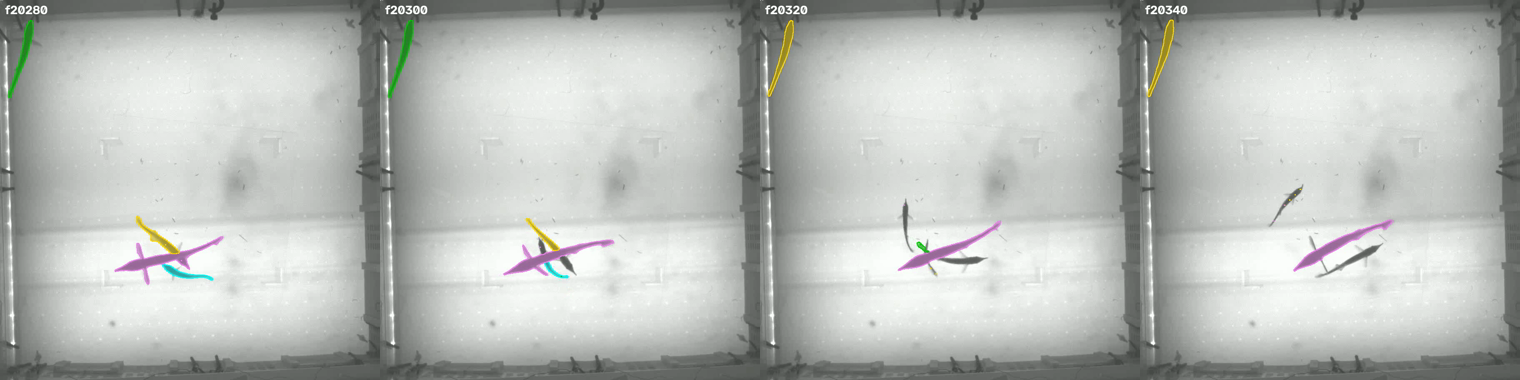

**6:54.5: labels 2 and 0 swap back**: 6:53.8 / 6:54.2 / 6:54.5 / 6:54.9

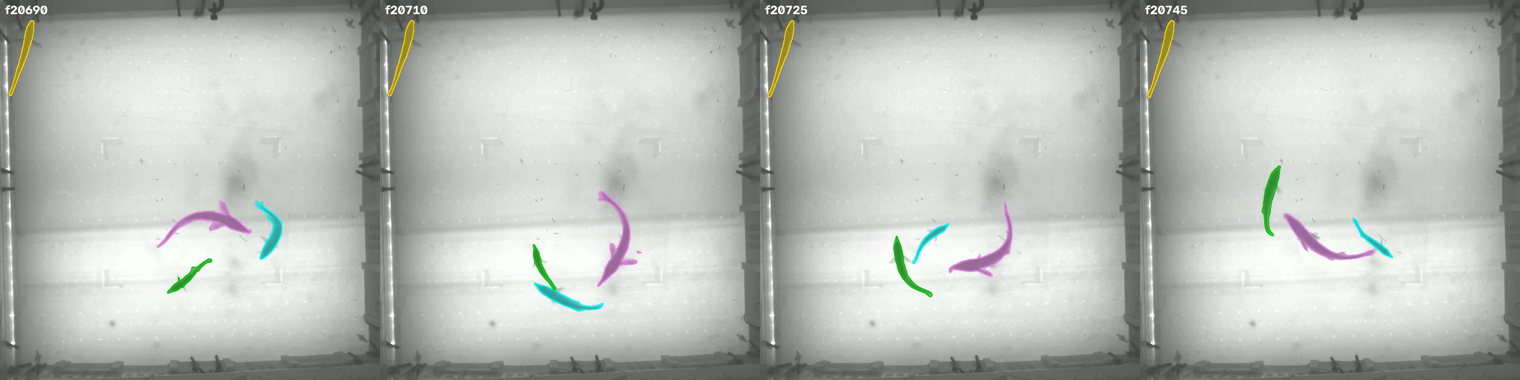

**7:44.5: labels 2 and 3 swap back**: 7:43.0 / 7:43.8 / 7:44.3 / 7:44.8

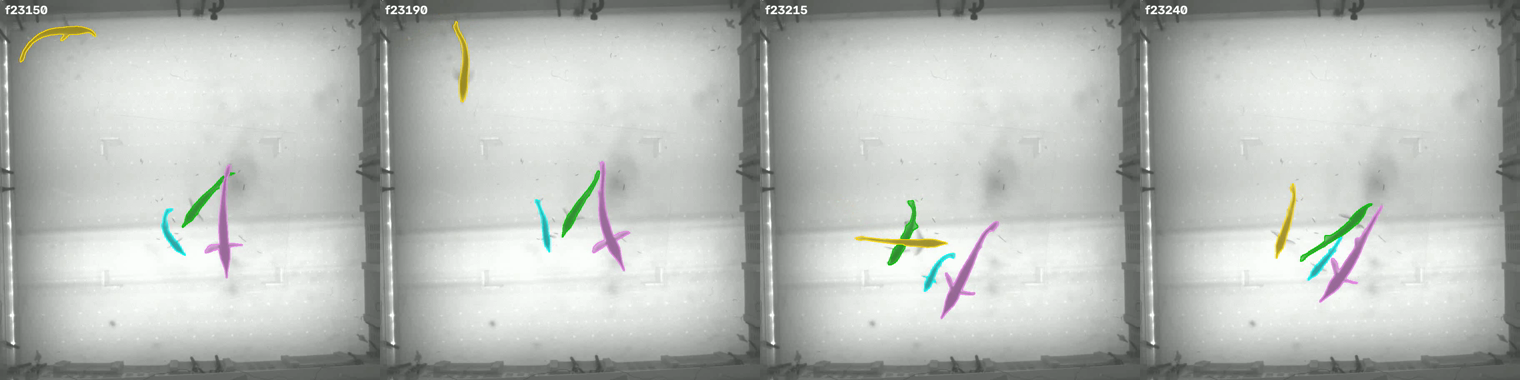

Clip of the whole episode, 6:43.0–7:48.0: `figures/identity_check/2024-10-23T15_18_28/clips/confirmed_swap_6m43-7m48.mp4`

In [4]:
# frames before / at / after each step of the confirmed swap
for title, frames in [('6:46.26: labels 2 and 3 exchange', [20280, 20300, 20320, 20340]),
                      ('6:54.5: labels 2 and 0 swap back', [20690, 20710, 20725, 20745]),
                      ('7:44.5: labels 2 and 3 swap back', [23150, 23190, 23215, 23240])]:
    png = ic.contact_sheet(MP4, frames, os.path.join(OUT, f'confirmed_{frames[1]}.png'), fps, width=380)
    display(Markdown(f'**{title}**: ' + ' / '.join(ts(f) for f in frames)))
    display(Image(png, width=1100))

clip = tc.make_clip(MP4, 20150, 23400 - 20150, fps, os.path.join(OUT, 'clips', 'confirmed_swap_6m43-7m48.mp4'),
                    f'Shiv {REC}  confirmed identity error 6:46.3-7:44.5', np.zeros(23400 - 20150, bool))
display(Markdown(f'Clip of the whole episode, 6:43.0–7:48.0: `{clip}`'))

## Clips of every event

Each clip runs from 3 s before to 3 s after the event, at real speed, with the event's times burned in.

In [5]:
paths = []
for t0, t1, a, b in zip(events['from'], events['to'], events.start, events.end):
    s = max(a - 3 * int(fps), 0)
    n = min(b + 3 * int(fps), len(area) - 1) - s + 1
    name = f'event_{t0.replace(":", "m")}-{t1.replace(":", "m")}.mp4'
    paths.append(tc.make_clip(MP4, s, n, fps, os.path.join(OUT, 'clips', name),
                              f'Shiv {REC}  potential swap {t0}-{t1}', np.zeros(n, bool)))
pd.DataFrame({'event': events['from'] + ' – ' + events['to'], 'clip': paths})

,event,clip
0,4:39.3 – 4:40.4,figures/identity_check/2024-10-23T15_18_28/cli...
1,5:58.6 – 6:00.5,figures/identity_check/2024-10-23T15_18_28/cli...
2,6:43.4 – 7:06.7,figures/identity_check/2024-10-23T15_18_28/cli...
3,7:12.8 – 7:18.3,figures/identity_check/2024-10-23T15_18_28/cli...
4,7:28.3 – 7:29.8,figures/identity_check/2024-10-23T15_18_28/cli...
5,7:38.9 – 7:51.8,figures/identity_check/2024-10-23T15_18_28/cli...
6,8:35.9 – 8:37.2,figures/identity_check/2024-10-23T15_18_28/cli...
7,8:52.2 – 8:54.9,figures/identity_check/2024-10-23T15_18_28/cli...
8,9:37.2 – 9:38.6,figures/identity_check/2024-10-23T15_18_28/cli...
9,9:53.4 – 9:59.5,figures/identity_check/2024-10-23T15_18_28/cli...


## Summary for this video
* **One real identity error**: 6:46.3–7:44.5 (58 s). Labels 2, 3 and 0 are mixed up for the first 8 s, then labels 2 and 3 for 50 s. See the table above.
* **All other candidates are false alarms**: label 2 at the wall, where it looks smaller and so close to fish 3's size (they differ by only 1.18×), or label 3 / 0 partly hidden under the large fish.
* **What this says about the metrics**: the swap itself was abrupt and caught as a centroid jump, but the frames during which identities stay wrong look normal to every per-frame check. A useful addition to the comparison would be **"% frames with a wrong identity"**, counted from a confirmed swap until it is resolved.